# Entrega 1 — Análise comparativa de representações vetoriais

**Projeto:** Ouvidoria Inteligente — triagem semântica de manifestações cidadãs
**Objetivo:** comparar representações **esparsas** (BoW, TF-IDF) com representações **densas** (embeddings de sentenças)
no problema real da ouvidoria: reconhecer que dois cidadãos estão falando do mesmo problema mesmo usando palavras diferentes.

**Roteiro**
1. Carregar e conhecer a base (`manifestacoes.json`, 40 manifestações).
2. Construir três representações esparsas: BoW, TF-IDF de palavras e TF-IDF de n-gramas de caracteres.
3. Construir três representações densas com `sentence-transformers` (três modelos multilíngues).
4. Calcular a similaridade de cosseno nos três pares pedidos e discutir.
5. Ir além dos três pares: olhar a distribuição completa de similaridades e medir, com o gabarito de duplicatas, quão bem cada representação separa "mesmo problema" de "problema diferente".
6. Conclusão sobre as limitações de cada abordagem.

> As funções reutilizadas por todos os notebooks e pelo app estão em `ouvidoria_core.py` (carregamento, embeddings, similaridade).

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import percentileofscore
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import roc_auc_score

import ouvidoria_core as oc

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)
oc.estilo_graficos()
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

## 1. A base de dados

In [2]:
df = oc.carregar_manifestacoes()
textos = df["texto"].tolist()
ids = df["id"].tolist()
posicao = {mid: k for k, mid in enumerate(ids)}   # "M003" -> linha 2

print(f"{len(df)} manifestações | {df['categoria_oficial'].nunique()} categorias")
print(f"Tamanho dos textos: {df['n_caracteres'].min()} a {df['n_caracteres'].max()} caracteres "
      f"(mediana {df['n_caracteres'].median():.0f})")
display(df["categoria_oficial"].value_counts().rename("manifestações").to_frame())
df.head()

40 manifestações | 5 categorias
Tamanho dos textos: 111 a 714 caracteres (mediana 167)


,manifestações
categoria_oficial,
infraestrutura,8
saúde,8
educação,8
meio ambiente,8
segurança,8


,id,data,categoria_oficial,texto,n_caracteres
0,M001,2026-06-02,infraestrutura,"A calçada da Rua XV de Novembro, entre a farmácia e o banco, está toda quebrada e com raízes expostas. Minha mãe tropeçou e machucou o j...",168
1,M002,2026-06-03,saúde,Há três semanas não tem losartana nem metformina na farmácia da unidade básica do Jardim América. Sou hipertenso e diabético e não tenho...,170
2,M003,2026-06-04,infraestrutura,"Tem um buraco enorme na Av. Brasil, em frente à padaria do número 1200. Só essa semana já vi dois motoqueiros caindo por causa dele. Alg...",155
3,M004,2026-06-05,educação,Meu filho estuda na Escola Municipal Monteiro Lobato e está há duas semanas sem merenda. As crianças voltam para casa com fome e a direç...,173
4,M005,2026-06-06,infraestrutura,"Poste apagado na Rua das Acácias, perto do número 85, faz quinze dias. A rua fica completamente escura e os moradores têm medo de sair à...",143


### Os três pares pedidos no enunciado

| Par | O que esperamos |
|---|---|
| M003 × M017 | **Mesmo problema** (buraco na Av. Brasil), escrito com vocabulário diferente: "buraco enorme / Av. Brasil / padaria" × "asfalto esburacado / avenida principal / panificadora" |
| M008 × M022 | **Mesmo problema** (posto do São José sem médico): "posto de saúde / sem médico" × "PSF / não tem doutor" |
| M008 × M031 | **Problemas sem relação** (saúde × iluminação) — é o controle negativo |

In [3]:
PARES = [
    ("M003", "M017", "duplicata — buraco na Av. Brasil"),
    ("M008", "M022", "duplicata — posto sem médico"),
    ("M008", "M031", "sem relação — saúde × iluminação"),
]
ROTULOS_PARES = [f"{a} × {b}" for a, b, _ in PARES]

for a, b, descricao in PARES:
    print(f"■ {a} × {b}  ({descricao})")
    print(f"   {a}: {textos[posicao[a]]}")
    print(f"   {b}: {textos[posicao[b]]}\n")

■ M003 × M017  (duplicata — buraco na Av. Brasil)
   M003: Tem um buraco enorme na Av. Brasil, em frente à padaria do número 1200. Só essa semana já vi dois motoqueiros caindo por causa dele. Alguém vai morrer ali.
   M017: Asfalto todo esburacado da avenida principal, pertinho da panificadora. As motos precisam desviar das crateras e uma hora vai acontecer um acidente grave.

■ M008 × M022  (duplicata — posto sem médico)
   M008: O posto de saúde do bairro São José está sem médico há mais de um mês. Chego às seis da manhã para pegar ficha e sou mandado embora sem consulta.
   M022: Falta atendimento no PSF da Vila São José. Não tem doutor faz semanas e a gente volta pra casa sem ser atendido.

■ M008 × M031  (sem relação — saúde × iluminação)
   M008: O posto de saúde do bairro São José está sem médico há mais de um mês. Chego às seis da manhã para pegar ficha e sou mandado embora sem consulta.
   M031: Lâmpada queimada na praça da Matriz. À noite não se enxerga nada e os idosos que c

## 2. Representações esparsas

Pré-processamento idêntico para todas: minúsculas, remoção de acentos (`strip_accents="unicode"`) e remoção de uma lista
curta de *stopwords* do português (`oc.STOPWORDS_PT`). Mantivemos **"não"** e **"sem"** no vocabulário porque, numa
reclamação, eles carregam o sentido ("sem médico", "não passou").

### 2.1 Bag-of-Words (BoW)
Cada texto vira um vetor de contagens com uma dimensão por palavra do vocabulário.

In [4]:
PARAMS_ESPARSOS = dict(strip_accents="unicode", lowercase=True, stop_words=oc.STOPWORDS_PT_SEM_ACENTO)

vet_bow = CountVectorizer(**PARAMS_ESPARSOS)
X_bow = vet_bow.fit_transform(textos)

esparsidade = 1 - X_bow.nnz / np.prod(X_bow.shape)
print(f"Vocabulário: {len(vet_bow.vocabulary_)} termos | matriz {X_bow.shape} | {esparsidade:.1%} das células são zero")

Vocabulário: 654 termos | matriz (40, 654) | 96.4% das células são zero


Por que o BoW vai (ou não) acertar? A similaridade de cosseno entre vetores de contagem só é positiva se os textos
**compartilham termos**. A tabela abaixo mostra exatamente quais termos cada par tem em comum.

In [5]:
analisador = vet_bow.build_analyzer()

def termos(mid):
    return set(analisador(textos[posicao[mid]]))

pd.DataFrame(
    [
        {
            "par": f"{a} × {b}",
            f"termos só no 1º": ", ".join(sorted(termos(a) - termos(b))),
            f"termos só no 2º": ", ".join(sorted(termos(b) - termos(a))),
            "termos em comum": ", ".join(sorted(termos(a) & termos(b))) or "(nenhum)",
        }
        for a, b, _ in PARES
    ]
).set_index("par")

,termos só no 1º,termos só no 2º,termos em comum
par,,,
M003 × M017,"1200, alguem, ali, av, brasil, buraco, caindo, causa, dois, enorme, frente, morrer, motoqueiros, numero, padaria, semana, vi","acidente, acontecer, asfalto, avenida, crateras, desviar, esburacado, grave, hora, motos, panificadora, pertinho, precisam, principal, todo",vai
M008 × M022,"bairro, chego, consulta, embora, ficha, mandado, manha, medico, mes, pegar, posto, saude, seis, sou","atendido, atendimento, casa, doutor, falta, faz, gente, nao, psf, semanas, vila, volta","jose, sem"
M008 × M031,"bairro, chego, consulta, embora, ficha, jose, mandado, manha, medico, mes, pegar, posto, saude, seis, sem, sou","ali, caminhavam, deixaram, enxerga, idosos, ir, lampada, matriz, nada, nao, noite, praca, queimada",(nenhum)


O par M003 × M017 — que é o **mesmo buraco** — compartilha apenas um termo genérico. "buraco" e "esburacado", "padaria"
e "panificadora", "Av." e "avenida", "motoqueiros" e "motos" são tokens diferentes para o BoW. Já M008 × M022 compartilha
só "jose" (parte do endereço) e "sem". Nenhum dos dois termos descreve o problema em si.

### 2.2 TF-IDF de palavras
O TF-IDF pondera cada termo pela raridade no corpus (IDF): palavras que aparecem em muitas manifestações pesam menos. Isso
ajuda a destacar termos discriminativos, mas **não cria sobreposição onde ela não existe**.

In [6]:
vet_tfidf = TfidfVectorizer(**PARAMS_ESPARSOS)
X_tfidf = vet_tfidf.fit_transform(textos)
vocab = np.array(vet_tfidf.get_feature_names_out())

def top_termos(mid, n=6):
    linha = X_tfidf[posicao[mid]].toarray().ravel()
    ordem = np.argsort(-linha)[:n]
    return ", ".join(f"{vocab[k]} ({linha[k]:.2f})" for k in ordem)

pd.DataFrame({"termos de maior peso TF-IDF": {mid: top_termos(mid) for mid in ["M003", "M017", "M008", "M022", "M031"]}})

,termos de maior peso TF-IDF
M003,"1200 (0.26), padaria (0.26), morrer (0.26), motoqueiros (0.26), causa (0.26), caindo (0.26)"
M017,"acontecer (0.27), principal (0.27), panificadora (0.27), pertinho (0.27), crateras (0.27), avenida (0.27)"
M008,"sem (0.34), seis (0.26), saude (0.26), pegar (0.26), embora (0.26), chego (0.26)"
M022,"psf (0.31), vila (0.31), atendido (0.31), doutor (0.31), falta (0.28), volta (0.28)"
M031,"queimada (0.31), lampada (0.31), matriz (0.31), deixaram (0.31), enxerga (0.31), caminhavam (0.31)"


### 2.3 TF-IDF de n-gramas de caracteres (3 a 5)
Uma variação esparsa que costuma ser esquecida: em vez de palavras, usamos pedaços de 3 a 5 caracteres dentro de cada
palavra (`analyzer="char_wb"`). Assim "**bura**co" e "es**bura**cado" passam a compartilhar dimensões. É um teste
justo para saber se o problema do BoW é só morfológico (flexões, derivações) ou se é **semântico** (sinônimos).

In [7]:
vet_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), strip_accents="unicode", lowercase=True, sublinear_tf=True)
X_char = vet_char.fit_transform(textos)
print(f"Vocabulário de n-gramas: {len(vet_char.vocabulary_)} dimensões")

Vocabulário de n-gramas: 6679 dimensões


## 3. Representações densas (embeddings de sentenças)

Comparamos três modelos multilíngues do `sentence-transformers`:

| Modelo | Dimensão | Observação |
|---|---|---|
| `paraphrase-multilingual-MiniLM-L12-v2` | 384 | Rápido; treinado para paráfrases (Reimers & Gurevych, 2019/2020). Lê no máximo **128 tokens**. |
| `paraphrase-multilingual-mpnet-base-v2` | 768 | Mesma receita, modelo base maior. Também lê no máximo 128 tokens. |
| `intfloat/multilingual-e5-small` | 384 | Treinado com aprendizado contrastivo em larga escala; exige o prefixo `"query: "`. Lê até 512 tokens. |

> O modelo `BAAI/bge-small-pt-v1.5`, sugerido no enunciado, não está disponível publicamente no Hugging Face Hub
> (a API retorna 401), por isso foi substituído pelo E5 multilíngue.

Os embeddings são **normalizados** (norma 1), então o cosseno é simplesmente o produto escalar.

In [8]:
embeddings = {}
for nome, cfg in oc.MODELOS.items():
    inicio = time.perf_counter()
    modelo = oc.carregar_modelo(nome)
    embeddings[cfg["curto"]] = oc.gerar_embeddings(modelo, textos, nome)
    print(f"{cfg['curto']:9s} -> matriz {embeddings[cfg['curto']].shape} em {time.perf_counter() - inicio:.1f}s")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10005.83it/s]

MiniLM    -> matriz (40, 384) em 15.7s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10012.19it/s]

MPNet     -> matriz (40, 768) em 8.4s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9606.46it/s]

E5-small  -> matriz (40, 384) em 8.0s


## 4. Similaridade de cosseno nos três pares

In [9]:
# Uma matriz de similaridade 40 x 40 por representação
similaridades = {
    "BoW": oc.matriz_similaridade(X_bow),
    "TF-IDF (palavras)": oc.matriz_similaridade(X_tfidf),
    "TF-IDF (char 3-5)": oc.matriz_similaridade(X_char),
    **{nome: oc.matriz_similaridade(E) for nome, E in embeddings.items()},
}

def sim_par(S, a, b):
    return float(S[posicao[a], posicao[b]])

tabela_pares = pd.DataFrame(
    {rep: [sim_par(S, a, b) for a, b, _ in PARES] for rep, S in similaridades.items()},
    index=[f"{a} × {b} ({d})" for a, b, d in PARES],
)
tabela_pares.style.format("{:.3f}").background_gradient(cmap=oc.cmap_sequencial(), axis=None, vmin=0, vmax=1)

,BoW,TF-IDF (palavras),TF-IDF (char 3-5),MiniLM,MPNet,E5-small
M003 × M017 (duplicata — buraco na Av. Brasil),0.059,0.041,0.081,0.711,0.762,0.920
M008 × M022 (duplicata — posto sem médico),0.184,0.136,0.109,0.818,0.810,0.934
M008 × M031 (sem relação — saúde × iluminação),0.000,0.000,0.022,0.206,0.297,0.892


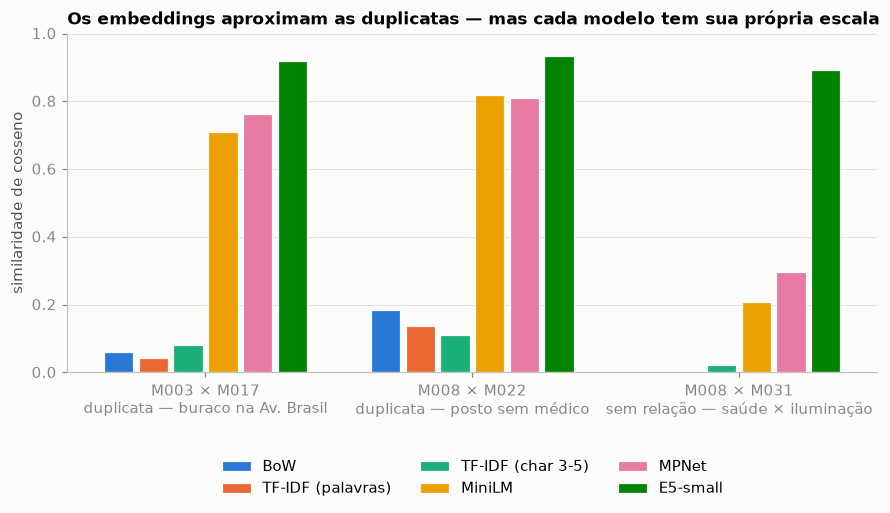

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 4))
largura = 0.13
x = np.arange(len(PARES))
for k, rep in enumerate(tabela_pares.columns):
    ax.bar(x + (k - 2.5) * largura, tabela_pares[rep], width=largura - 0.02,
           color=oc.PALETA[k], label=rep, edgecolor="#fcfcfb", linewidth=0.8)
ax.set_xticks(x, [f"{a} × {b}\n{d}" for a, b, d in PARES])
ax.set_ylabel("similaridade de cosseno")
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
ax.set_title("Os embeddings aproximam as duplicatas — mas cada modelo tem sua própria escala")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22))
fig.savefig(FIGURAS / "e1_pares_enunciado.png")
plt.show()

**Leitura direta da tabela**

* **Esparsas.** No par M003 × M017, que é o mesmo buraco, todas as representações esparsas dão cosseno abaixo de 0,1. Para
  elas, as duas reclamações são praticamente independentes. M008 × M022 sobe um pouco (≈0,11–0,18), mas só por causa
  de "São José" e "sem". Ou seja, o acerto vem do **endereço** e não do problema. O n-grama de caracteres ajuda pouco,
  porque a dificuldade não é morfológica: "padaria/panificadora", "médico/doutor" e "posto/PSF" são **sinônimos**, não
  variações da mesma palavra.
* **Densas (MiniLM, MPNet).** As duas duplicatas ficam entre 0,71 e 0,82 e o controle negativo fica entre 0,21 e 0,30.
  Aqui está a vantagem central dos embeddings: "asfalto esburacado" ≈ "buraco enorme" e "não tem doutor" ≈ "sem médico".
* **E5.** Também ordena corretamente (0,92 e 0,93 para as duplicatas contra 0,89 para o controle), mas **quase todos** os
  780 pares da base (769) ficam acima de 0,85. Um cosseno de 0,89 entre "posto sem médico" e "lâmpada queimada" parece alto, mas não quer dizer que
  os textos são parecidos. É o comportamento típico do E5, que concentra todos os vetores num cone estreito do espaço
  (anisotropia). **O valor absoluto do cosseno não é comparável entre modelos.** Por isso a seção 5 compara
  posições relativas.

## 5. Além dos três pares: o que a distribuição completa mostra

Três pares são pouca evidência. Com 40 manifestações temos **780 pares distintos**, e o arquivo `duplicatas_gabarito.json`
marca os 6 pares que são duplicatas reais (15% das manifestações). Com isso podemos medir, para cada representação:

* **percentil** de cada par pedido dentro da distribuição dos 780 pares (0,89 no E5 pode estar "no meio da multidão");
* **AUC-ROC**: probabilidade de uma duplicata real receber cosseno maior que um par qualquer que não é duplicata
  (1,0 = separação perfeita; 0,5 = sorteio). É uma métrica que **não depende de limiar nem de escala**.

In [11]:
gabarito = oc.carregar_gabarito()
pares_reais = oc.pares_gabarito(gabarito)
iu, ju = np.triu_indices(len(ids), k=1)
eh_duplicata = np.array([frozenset((ids[a], ids[b])) in pares_reais for a, b in zip(iu, ju)])

linhas = []
for rep, S in similaridades.items():
    todos = S[iu, ju]
    linha = {"representação": rep, "média (780 pares)": todos.mean(), "p99": np.percentile(todos, 99),
             "média das 6 duplicatas": todos[eh_duplicata].mean(),
             "AUC duplicata × resto": roc_auc_score(eh_duplicata, todos)}
    for a, b, _ in PARES:
        linha[f"percentil {a}×{b}"] = percentileofscore(todos, sim_par(S, a, b))
    linhas.append(linha)

diagnostico = pd.DataFrame(linhas).set_index("representação")
diagnostico.style.format("{:.3f}").format("{:.1f}", subset=[c for c in diagnostico if c.startswith("percentil")])

,média (780 pares),p99,média das 6 duplicatas,AUC duplicata × resto,percentil M003×M017,percentil M008×M022,percentil M008×M031
representação,,,,,,,
BoW,0.051,0.273,0.199,0.921,67.2,95.3,21.5
TF-IDF (palavras),0.026,0.163,0.153,0.956,77.2,98.3,21.5
TF-IDF (char 3-5),0.076,0.209,0.193,0.907,63.7,82.7,0.9
MiniLM,0.288,0.668,0.743,1.000,99.5,100.0,32.6
MPNet,0.345,0.716,0.808,1.000,99.4,99.7,40.9
E5-small,0.882,0.922,0.936,0.999,98.7,99.6,74.4


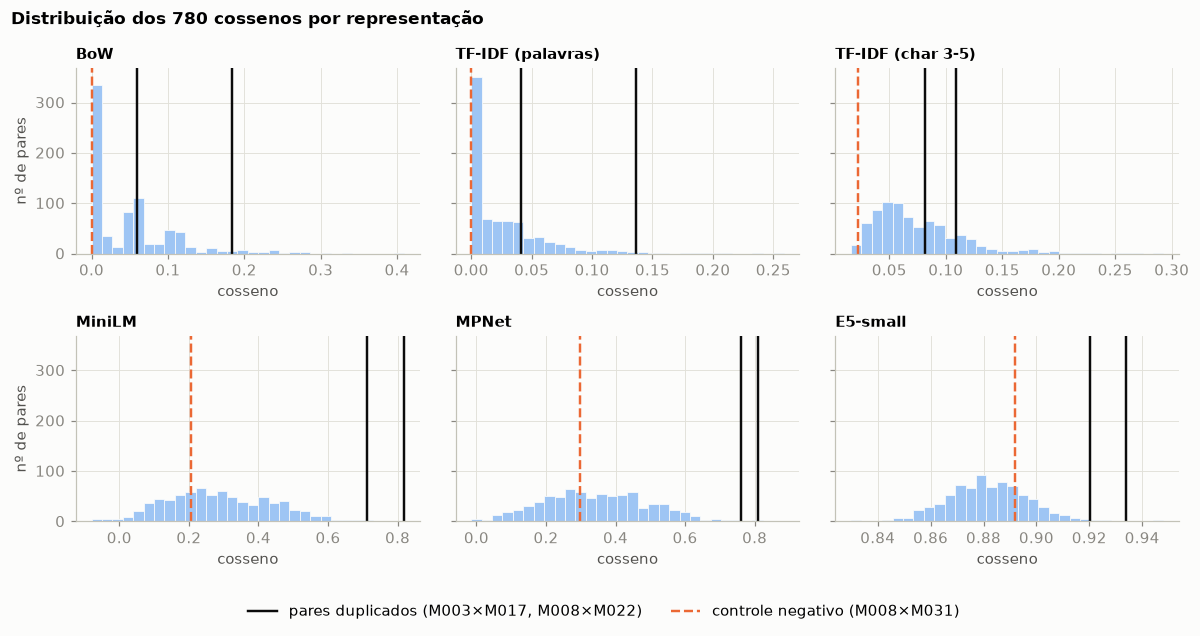

In [12]:
fig, eixos = plt.subplots(2, 3, figsize=(11, 5.6), sharey=True)
for ax, (rep, S) in zip(eixos.ravel(), similaridades.items()):
    todos = S[iu, ju]
    ax.hist(todos, bins=30, color="#9ec5f4", edgecolor="#fcfcfb", linewidth=0.5)
    for (a, b, d), estilo in zip(PARES, ["-", "-", "--"]):
        cor = "#0b0b0b" if d.startswith("duplicata") else "#eb6834"
        ax.axvline(sim_par(S, a, b), color=cor, linestyle=estilo, linewidth=1.6)
    ax.set_title(rep, fontsize=10)
    ax.set_xlabel("cosseno")
eixos[0, 0].set_ylabel("nº de pares")
eixos[1, 0].set_ylabel("nº de pares")
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], color="#0b0b0b", lw=1.6, label="pares duplicados (M003×M017, M008×M022)"),
                    Line2D([], [], color="#eb6834", lw=1.6, ls="--", label="controle negativo (M008×M031)")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Distribuição dos 780 cossenos por representação", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIGURAS / "e1_distribuicoes.png")
plt.show()

**O que a distribuição revela**

* Nas esparsas, a massa dos pares está em **zero**, porque a maioria dos textos não compartilha nenhum termo relevante. A
  duplicata M003 × M017 fica entre os percentis 64 e 77, indistinguível de dezenas de pares aleatórios. A AUC das
  esparsas (≈0,91–0,96) não é baixa, mas isso acontece porque **4 das 6 duplicatas repetem o nome do lugar** ("Rua das
  Acácias", "Sete de Setembro", "Praça Tiradentes", "São José"). Quando o cidadão não cita o endereço com as mesmas
  palavras, o método esparso falha.
* Nos três modelos densos, as duplicatas ficam no **topo** da distribuição (percentil ≥ 98,7) e a AUC fica praticamente em
  1,0. O controle negativo M008 × M031 fica no miolo da distribuição (percentis 33 a 74), inclusive no E5, cujo valor bruto (0,89) parecia alto.
  O E5 **ordena** tão bem quanto os outros. O que ele não tem é uma escala absoluta intuitiva. Isso vai pesar na escolha
  do limiar de duplicatas (Entrega 2).

### 5.1 Efeito das stopwords no BoW

Um detalhe metodológico: sem remover stopwords, o BoW dá similaridade **positiva** ao controle negativo M008 × M031,
porque os dois textos compartilham artigos e preposições.

In [13]:
X_bow_bruto = CountVectorizer(strip_accents="unicode", lowercase=True).fit_transform(textos)
S_bruto = oc.matriz_similaridade(X_bow_bruto)
pd.DataFrame(
    {"BoW sem remover stopwords": [sim_par(S_bruto, a, b) for a, b, _ in PARES],
     "BoW removendo stopwords": [sim_par(similaridades["BoW"], a, b) for a, b, _ in PARES]},
    index=ROTULOS_PARES,
).style.format("{:.3f}")

,BoW sem remover stopwords,BoW removendo stopwords
M003 × M017,0.077,0.059
M008 × M022,0.198,0.184
M008 × M031,0.122,0.000


Remover stopwords zera o controle negativo e também reduz a duplicata M003 × M017 (0,077 → 0,059). Parte da
similaridade que ela tinha vinha de palavras vazias. Nas representações esparsas, a similaridade mede **sobreposição lexical**. Sem
stopwords ela fica mais honesta, mas continua sendo lexical.

## 6. Conclusão — limitações de cada abordagem

**BoW** trata cada palavra como um símbolo isolado. É simples, interpretável e barato, mas é cego a sinônimos
("padaria/panificadora", "médico/doutor"), a variações morfológicas ("buraco/esburacado") e à ordem das palavras. Na
ouvidoria, isso faz exatamente o que o enunciado descreve: "asfalto esburacado" e "buraco enorme" têm cosseno de 0,06.
Além disso, o resultado depende muito do pré-processamento: stopwords, sozinhas, criam similaridades espúrias. **TF-IDF**
corrige o peso das palavras, destacando termos raros e reduzindo os comuns, mas herda a mesma limitação: se não há termo
em comum, não há similaridade. Quando há, costuma ser o **endereço** (um nome próprio raro, com IDF alto), e não o
problema, o que pode unir reclamações diferentes da mesma rua e separar a mesma reclamação escrita de outro jeito.
**N-gramas de caracteres** capturam parte da morfologia, mas não resolvem sinônimos e ainda aumentam muito a
dimensionalidade. **Embeddings de sentenças** resolvem o problema central: aproximam paráfrases (0,71–0,82 nas duplicatas
contra 0,21–0,30 no controle, com MiniLM/MPNet) e separam duplicatas do resto com AUC ≈ 1,0. Eles também têm
limitações: (i) são caixas-pretas, sem explicação de *por que* dois textos são parecidos; (ii) a **escala do cosseno
muda de modelo para modelo** (o E5 coloca quase tudo acima de 0,85), então limiares fixos precisam ser calibrados por
modelo; (iii) medem proximidade **temática**, não identidade do caso: dois buracos em ruas diferentes também ficam
próximos, e distinguir "mesmo problema" de "mesmo tipo de problema" continua exigindo cuidado (Entrega 2); e (iv) MiniLM
e MPNet leem só 128 tokens, então **o final das manifestações longas é ignorado**, o que motiva o chunking (Entrega 3).
Na prática, a melhor arquitetura combina as duas famílias: embeddings para recuperar candidatos semanticamente próximos
e sinais lexicais (endereço, nomes de equipamentos públicos) para confirmar se é o mesmo caso.